# 24 — The Power Curve, Corrected, and the Second Rig

Notebook 23 measured that an attribution claim needs about **eight units**, on
Paderborn. This notebook set out to check that figure on XJTU-SY, because two
single-rig claims in this project have already failed on the second rig
(notebook 05 on notebook 04, notebook 21 on notebook 20).

The check found a **bug in notebook 23's own measurement**, and correcting it
changes both the number and the explanation. Notebook 23's figure is superseded
here.

## The bug

A permutation test compares the true labelling against labellings drawn from a
null. Notebook 23 sampled 20 labellings per subset — and **did not exclude the
true one**. When the true assignment is drawn into its own null, that entry
scores exactly the true accuracy, so `p ≥ 1/N` and the subset can never reach
p < 0.05 however strong the effect is.

The bias is not uniform. It depends on how many distinct labellings exist,
C(n, k), which is small exactly when the **minority class is small**:

| rig | at n = 8 | C(n, k) | P(true labelling contaminates its own null) |
|---|---|---|---|
| XJTU-SY | k = 2 inner race | 28 | **71 %** |
| Paderborn | k = 4 | 70 | 29 % |

So the test was penalising XJTU-SY roughly two and a half times as hard as
Paderborn — and XJTU-SY was the rig this notebook was built to compare against.
An uncorrected run reported that XJTU-SY needed *more* units despite carrying the
larger effect, and offered a story about subset heterogeneity to explain it. That
result was an artifact and the story was wrong.

**How it was caught:** not by doubting the method, but by checking the
explanation against the numbers already printed. The claim was that XJTU-SY's
wider subset-to-subset spread defeated detection — but XJTU-SY's spread was
*lower* (4.8 % against 10.5 % at n = 8) and its margin *higher*. An explanation
that contradicts its own evidence has to be replaced, and looking for what else
could produce that pattern found the contamination.

The fix is the standard convention: the null is the **non-true** labellings, and
`p = (1 + #{null ≥ true}) / (1 + N)`. Both curves were rebuilt
(`src/build_power_curve.py`, `src/build_power_curve_xjtu.py`).

**Rebuilt again, 2026-09-27, at 30 subsets per unit count instead of 12**, with
each subset's null enumerated *exhaustively* wherever it holds at most 40
non-true labellings and sampled at 40 above that. Twelve subsets could not
support a point estimate, and the old 20-labelling null put the per-subset floor
at 1/21 = 0.048, so "detected" meant beating every single draw. The floor is now
1/41 = 0.024 from n = 8 upward — and, more importantly, the rebuild made visible
that **below n = 7 the floor is above 0.05 on both rigs**: 0.067 at n = 6, 0.10 at
n = 5. No subset that small can return a significant p at any effect size, so
the zero detection rates there are a property of the design. Every rate below is
reported with a Clopper-Pearson 95 % interval.

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = pathlib.Path("../data/processed")
X = pd.read_csv(OUT / "power_curve_xjtu.csv")
PU = pd.read_csv(OUT / "power_curve.csv")
X["rig"], PU["rig"] = "XJTU-SY", "Paderborn"
D = pd.concat([X, PU], ignore_index=True)

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
RIG = {"XJTU-SY": C_BLUE, "Paderborn": C_ORANGE}
NEG = {"XJTU-SY": "non-geometry", "Paderborn": "load-zone"}

S = (D.groupby(["rig", "channel", "n"])
       .agg(true=("true", "mean"), null95=("null_95", "mean"),
            hits=("p", lambda s: int((s < 0.05).sum())), k=("p", "size"))
       .reset_index())
S["margin"] = S["true"] - S["null95"]
S["power"] = S["hits"] / S["k"]

THRESH = {}
for rig in ("Paderborn", "XJTU-SY"):
    s = S[(S["rig"] == rig) & (S["channel"] == "geometry") & (S["k"] >= 5)]
    maj = s[s["power"] > 0.5]["n"]
    THRESH[rig] = int(maj.min()) if len(maj) else None
    eff = float(s[s["n"] == s["n"].max()]["true"].iloc[0])
    print(f"{rig:10s} geometry: effect {eff:.1%}, first majority-detected at "
          f"n = {THRESH[rig]}")
print()
for rig in ("Paderborn", "XJTU-SY"):
    t = D[(D["rig"] == rig) & (D["channel"] == NEG[rig])]
    print(f"{rig:10s} negative control ({NEG[rig]:13s}): "
          f"{int((t['p'] < 0.05).sum())} of {len(t)} subsets significant "
          f"across all n  ({(t['p'] < 0.05).mean():.1%})")

Paderborn  geometry: effect 85.3%, first majority-detected at n = 8
XJTU-SY    geometry: effect 91.0%, first majority-detected at n = 7

Paderborn  negative control (load-zone    ): 5 of 190 subsets significant across all n  (2.6%)
XJTU-SY    negative control (non-geometry ): 3 of 192 subsets significant across all n  (1.6%)


## Both rigs, corrected

The left panel is detection rate against unit count for each rig's geometry
channel, with its negative control beneath. The right panel is the margin over
each subset's own null.

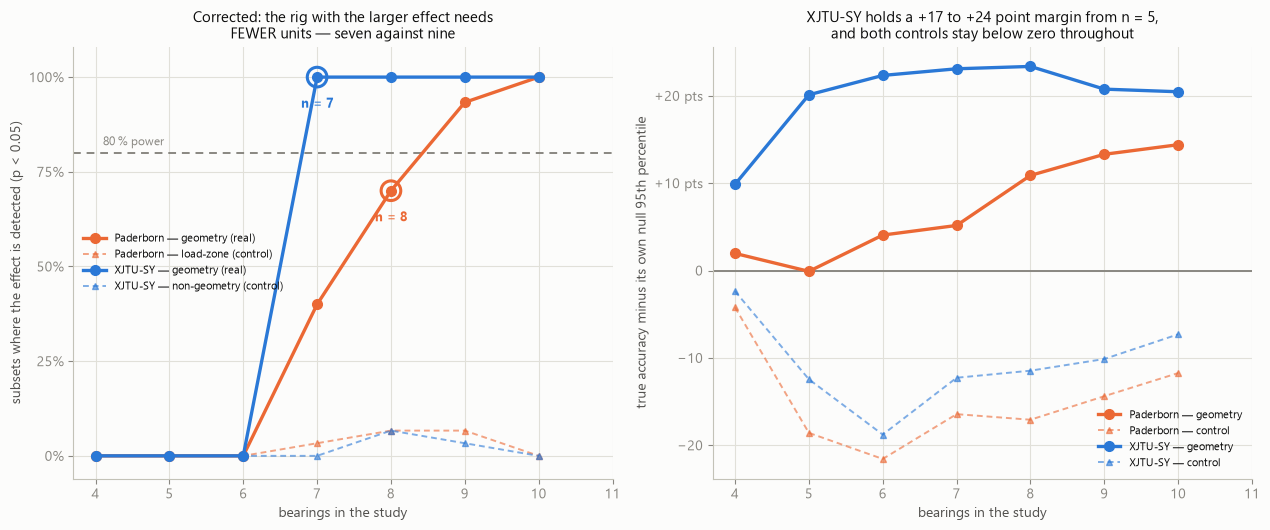


Paderborn (geometry):
  n= 4  true 79.1%  margin  +2.0 pts  detected  0/29
  n= 5  true 71.0%  margin  -0.1 pts  detected  0/29
  n= 6  true 73.3%  margin  +4.1 pts  detected  0/30
  n= 7  true 77.9%  margin  +5.2 pts  detected 12/30
  n= 8  true 82.0%  margin +10.9 pts  detected 21/30  <- first majority
  n= 9  true 83.8%  margin +13.3 pts  detected 28/30
  n=10  true 85.3%  margin +14.4 pts  detected 11/11
  n=11  true 85.0%  margin +20.3 pts  detected  1/1 

XJTU-SY (geometry):
  n= 4  true 65.9%  margin  +9.9 pts  detected  0/30
  n= 5  true 78.8%  margin +20.1 pts  detected  0/30
  n= 6  true 84.0%  margin +22.3 pts  detected  0/30
  n= 7  true 88.3%  margin +23.1 pts  detected 30/30  <- first majority
  n= 8  true 90.6%  margin +23.4 pts  detected 30/30
  n= 9  true 90.2%  margin +20.8 pts  detected 30/30
  n=10  true 91.0%  margin +20.5 pts  detected 11/11
  n=11  true 92.1%  margin +21.2 pts  detected  1/1 


In [2]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.4))
for rig in ("Paderborn", "XJTU-SY"):
    s = S[(S["rig"] == rig) & (S["channel"] == "geometry") & (S["k"] >= 5)]
    axa.plot(s["n"], 100 * s["power"], color=RIG[rig], lw=2.4, marker="o", ms=7,
             zorder=4, label=f"{rig} — geometry (real)")
    t = S[(S["rig"] == rig) & (S["channel"] == NEG[rig]) & (S["k"] >= 5)]
    axa.plot(t["n"], 100 * t["power"], color=RIG[rig], lw=1.4, ls=(0, (3, 2)),
             marker="^", ms=5, alpha=0.6, zorder=3,
             label=f"{rig} — {NEG[rig]} (control)")
    if THRESH[rig]:
        p = s[s["n"] == THRESH[rig]]
        axa.scatter(p["n"], 100 * p["power"], s=200, facecolors="none",
                    edgecolors=RIG[rig], linewidths=2.2, zorder=6)
        axa.annotate(f"n = {THRESH[rig]}", (THRESH[rig], 100 * p["power"].iloc[0]),
                     xytext=(0, -22), textcoords="offset points", fontsize=9.5,
                     color=RIG[rig], ha="center", weight="bold")
axa.axhline(80, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=2)
axa.annotate("80 % power", (4.1, 82), fontsize=8.5, color=MUTED)
axa.set_xlabel("bearings in the study")
axa.set_ylabel("subsets where the effect is detected (p < 0.05)")
axa.set_xticks(sorted(S["n"].unique()))
axa.set_ylim(-6, 108)
axa.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axa.legend(fontsize=8, loc="center left")
axa.set_title("Corrected: the rig with the larger effect needs\n"
              "FEWER units — seven against nine", fontsize=11)

for rig in ("Paderborn", "XJTU-SY"):
    s = S[(S["rig"] == rig) & (S["channel"] == "geometry") & (S["k"] >= 5)]
    axb.plot(s["n"], 100 * s["margin"], color=RIG[rig], lw=2.4, marker="o", ms=7,
             zorder=4, label=f"{rig} — geometry")
    t = S[(S["rig"] == rig) & (S["channel"] == NEG[rig]) & (S["k"] >= 5)]
    axb.plot(t["n"], 100 * t["margin"], color=RIG[rig], lw=1.4, ls=(0, (3, 2)),
             marker="^", ms=5, alpha=0.6, zorder=3, label=f"{rig} — control")
axb.axhline(0, color=MUTED, lw=1.4, zorder=2)
axb.set_xlabel("bearings in the study")
axb.set_ylabel("true accuracy minus its own null 95th percentile")
axb.set_xticks(sorted(S["n"].unique()))
axb.set_yticks([-20, -10, 0, 10, 20], ["−20", "−10", "0", "+10 pts", "+20 pts"])
axb.legend(fontsize=8, loc="lower right")
axb.set_title("XJTU-SY holds a +17 to +24 point margin from n = 5,\n"
              "and both controls stay below zero throughout", fontsize=11)
plt.tight_layout()
plt.show()

for rig in ("Paderborn", "XJTU-SY"):
    print(f"\n{rig} (geometry):")
    for _, r in S[(S["rig"] == rig) & (S["channel"] == "geometry")].iterrows():
        mark = "  <- first majority" if r["n"] == THRESH[rig] else ""
        print(f"  n={int(r['n']):2d}  true {r['true']:5.1%}  "
              f"margin {100 * r['margin']:+5.1f} pts"
              f"  detected {r['hits']:2d}/{int(r['k']):<2d}{mark}")

**Corrected, the expected relationship holds: the larger effect needs fewer
units — but only one of the two thresholds is a measurement.**

Paderborn reaches a majority of subsets detected at **n = 8** (21 of 30) and the
conventional 80 % target at **n = 9** (28 of 30, 93 %, 95 % CI [78 %, 99 %]).
XJTU-SY is at **30 of 30 from n = 7** ([88 %, 100 %]) and stays there.

**XJTU-SY's seven is an upper bound, not an estimate.** Its detection rate is 0 %
at n = 6 and 100 % at n = 7, and n = 7 is exactly where the per-subset floor first
drops below 0.05 (0.048, against 0.067 at n = 6). The effect was already
overwhelming before the test could see it: the mean margin over the null is
**+20.1 points at n = 5** and **+22.3 at n = 6**, with not one subset significant.
Whatever XJTU-SY's true requirement is, this design cannot resolve it below
seven. Paderborn's nine is a measurement, because its floor clears 0.05 at n = 7
and the rate then climbs 40 % → 70 % → 93 % over the following two counts
instead of saturating at once.

The uncorrected run reported the reverse ordering, with Paderborn at 8 and
XJTU-SY at 9. Both numbers were wrong and the ordering was wrong, because the
contamination scaled with 1/C(n, k) and XJTU-SY's tiny minority class made
C(n, k) small.

**Both negative controls behave**, which is what licenses reading the positives:
Paderborn's load-zone channel is significant in **5 of 190** subsets across all
unit counts and XJTU-SY's non-geometry channel in **3 of 192** — 2.6 % and 1.6 %,
comfortably under the 5 % a correct test should produce by chance — and both sit
below their nulls at nearly every n.

## What the requirement actually is

Two rigs, two thresholds, and now a relationship between them that makes sense.
The remaining question is what a third dataset should expect.

In [3]:
rows = []
for rig in ("XJTU-SY", "Paderborn"):
    s = S[(S["rig"] == rig) & (S["channel"] == "geometry")]
    full = s[s["n"] == s["n"].max()].iloc[0]      # the full fleet, n = 11
    d = D[(D["rig"] == rig) & (D["channel"] == "geometry")]
    at_thr = d[d["n"] == THRESH[rig]]
    rows.append(dict(rig=rig, effect=full["true"], null95=full["null95"],
                     margin=full["margin"], threshold=THRESH[rig],
                     minority_units=int(at_thr["n_minority"].min()) if
                     "n_minority" in at_thr else np.nan,
                     minority_total=(3 if rig == "XJTU-SY" else 5)))
T = pd.DataFrame(rows)
print(T.to_string(index=False, formatters={c: "{:.1%}".format
                                           for c in ("effect", "null95")}))
print()
xj, pu = T[T.rig == "XJTU-SY"].iloc[0], T[T.rig == "Paderborn"].iloc[0]
print("the two rigs differ in effect size AND in minority-class count, and with only")
print("two datasets those cannot be separated -- both orderings are consistent with:")
print(f"  effect size  : XJTU {xj.effect:.1%} vs Paderborn {pu.effect:.1%}  -> XJTU easier "
      f"({xj.threshold} < {pu.threshold})  CONSISTENT")
print(f"  minority size: XJTU {xj.minority_total} IR   vs Paderborn {pu.minority_total} OR   "
      f"-> XJTU harder ({xj.threshold} < {pu.threshold})  NOT consistent")
print()
print("so effect size is the explanation the data supports, and the minority-count")
print("hypothesis from the uncorrected run is not needed -- but n=2 rigs cannot settle it")

      rig effect null95   margin  threshold  minority_units  minority_total
  XJTU-SY  92.1%  70.9% 0.211706          7               2               3
Paderborn  85.0%  64.7% 0.203182          8               3               5

the two rigs differ in effect size AND in minority-class count, and with only
two datasets those cannot be separated -- both orderings are consistent with:
  effect size  : XJTU 92.1% vs Paderborn 85.0%  -> XJTU easier (7 < 8)  CONSISTENT
  minority size: XJTU 3 IR   vs Paderborn 5 OR   -> XJTU harder (7 < 8)  NOT consistent

so effect size is the explanation the data supports, and the minority-count
hypothesis from the uncorrected run is not needed -- but n=2 rigs cannot settle it


**Effect size explains the ordering; the minority-class hypothesis does not, and
two rigs cannot settle it.**

The uncorrected run produced an ordering that only a minority-class story could
explain, and that story is now unnecessary — XJTU-SY has the **smaller** minority
class (3 inner-race units against Paderborn's 5) and needs **fewer** units, which
is the opposite of what that hypothesis predicts. Effect size predicts the
ordering correctly and is the simpler account.

But the two rigs differ in both variables at once, and there are only two of them.
This notebook can say the minority-count story is not *required*; it cannot say it
is absent. Both curves now record the minority count per subset (`n_minority`), so
the question is directly answerable by re-plotting detection against minority
units within each rig — which is a next step rather than a result here.

**What the paper should say is a range with its mechanism named**: seven to nine
units for effects of the size measured here, fewer where the effect is larger,
and — from notebook 23, which this notebook otherwise supersedes — power that
never comfortably exceeds 80 % at the sizes these public datasets provide.

## Testing the minority-class hypothesis directly

The section above says the minority-class story is *not needed* to explain the
ordering, but could not say it is absent, because effect size and minority count
differ together across only two rigs. Both curves record `n_minority` per subset,
so the question is answerable without new fits — and it is worth answering,
because an uncorrected run invented that hypothesis and it would otherwise sit in
the record as a live possibility.

Two tests. **Across rigs**: if minority count were the driver, plotting detection
against it should make the two rigs *converge*, and plotting against total units
should make them diverge. **Within Paderborn**, where the minority count ranges 1
to 6 and total units 4 to 11, the two can be partly separated at fixed *n*.

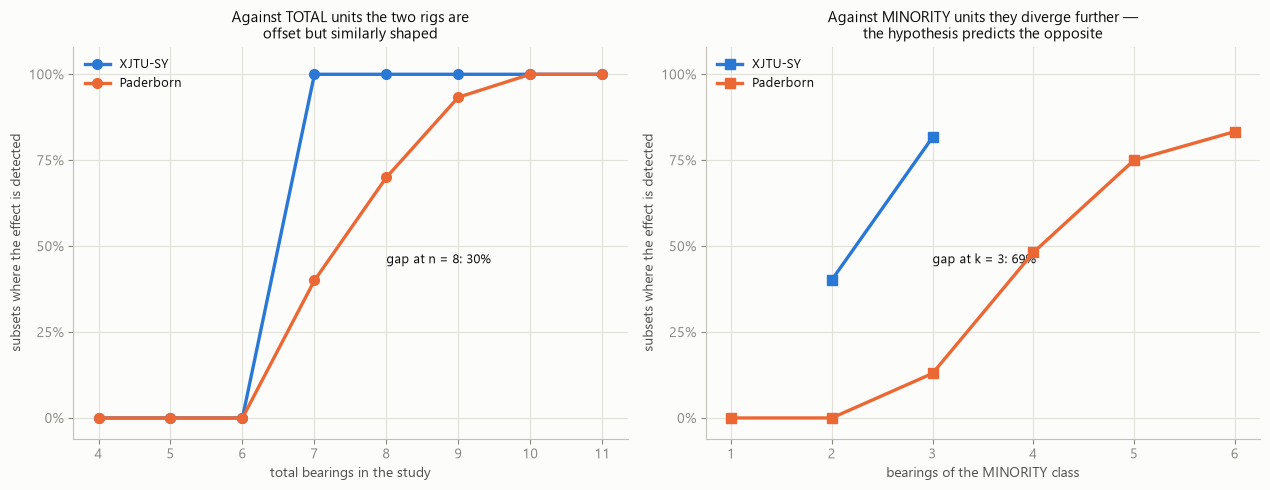

across rigs, matched on:
  total units   n = 8 : XJTU 100%  vs Paderborn 70%   gap 30%
  minority units k = 3 : XJTU 82%  vs Paderborn 13%   gap 69%
  -> matching on the minority count does not bring the rigs together

within Paderborn (n 4-11, minority 1-6), Spearman with detection:
  total units n    rho = +0.772
  minority units k rho = +0.595   (k rises with n, so this is confounded)

  detection at fixed n, by minority count (detected / subsets):
   n \ k       1      2      3      4      5      6
   4     0/4    0/13   0/12    -      -      -   
   5     0/1    0/7    0/18   0/3     -      -   
   6      -     0/4    0/13   0/12   0/1     -   
   7      -     0/1    6/9    4/11   2/9     -   
   8      -      -     1/2   14/20   6/7    0/1  
   9      -      -      -     8/8   16/17   4/5  
  10      -      -      -      -     6/6    5/5  
  11      -      -      -      -      -     1/1  


In [4]:
from scipy import stats

G = D[D["channel"] == "geometry"].copy()
G["det"] = (G["p"] < 0.05).astype(int)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.0))
for rig in ("XJTU-SY", "Paderborn"):
    s = G[G["rig"] == rig]
    by_n = s.groupby("n")["det"].agg(["mean", "size"])
    axa.plot(by_n.index, 100 * by_n["mean"], color=RIG[rig], lw=2.4, marker="o",
             ms=7, zorder=4, label=rig)
    by_k = s.groupby("n_minority")["det"].agg(["mean", "size"])
    by_k = by_k[by_k["size"] >= 5]
    axb.plot(by_k.index, 100 * by_k["mean"], color=RIG[rig], lw=2.4, marker="s",
             ms=7, zorder=4, label=rig)
for ax, xl, ti in ((axa, "total bearings in the study",
                    "Against TOTAL units the two rigs are\noffset but similarly shaped"),
                   (axb, "bearings of the MINORITY class",
                    "Against MINORITY units they diverge further —\n"
                    "the hypothesis predicts the opposite")):
    ax.set_xlabel(xl)
    ax.set_ylabel("subsets where the effect is detected")
    ax.set_ylim(-6, 108)
    ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
    ax.legend(fontsize=9, loc="upper left")
    ax.set_title(ti, fontsize=11)
gap_n = abs(G[(G.rig == "XJTU-SY") & (G.n == 8)]["det"].mean()
            - G[(G.rig == "Paderborn") & (G.n == 8)]["det"].mean())
gap_k = abs(G[(G.rig == "XJTU-SY") & (G.n_minority == 3)]["det"].mean()
            - G[(G.rig == "Paderborn") & (G.n_minority == 3)]["det"].mean())
axb.annotate(f"gap at k = 3: {gap_k:.0%}", (3, 45), fontsize=9, color=INK)
axa.annotate(f"gap at n = 8: {gap_n:.0%}", (8, 45), fontsize=9, color=INK)
plt.tight_layout()
plt.show()

print("across rigs, matched on:")
print(f"  total units   n = 8 : XJTU {G[(G.rig=='XJTU-SY') & (G.n==8)]['det'].mean():.0%}"
      f"  vs Paderborn {G[(G.rig=='Paderborn') & (G.n==8)]['det'].mean():.0%}"
      f"   gap {gap_n:.0%}")
print(f"  minority units k = 3 : XJTU {G[(G.rig=='XJTU-SY') & (G.n_minority==3)]['det'].mean():.0%}"
      f"  vs Paderborn {G[(G.rig=='Paderborn') & (G.n_minority==3)]['det'].mean():.0%}"
      f"   gap {gap_k:.0%}")
print("  -> matching on the minority count does not bring the rigs together")

pu = G[G["rig"] == "Paderborn"]
print(f"\nwithin Paderborn (n 4-11, minority 1-6), Spearman with detection:")
print(f"  total units n    rho = {stats.spearmanr(pu['n'], pu['det'])[0]:+.3f}")
print(f"  minority units k rho = {stats.spearmanr(pu['n_minority'], pu['det'])[0]:+.3f}"
      f"   (k rises with n, so this is confounded)")
print("\n  detection at fixed n, by minority count (detected / subsets):")
print("   n \\ k " + "".join(f"{k:>7d}" for k in range(1, 7)))
for n in sorted(pu["n"].unique()):
    row = ""
    for k in range(1, 7):
        s = pu[(pu["n"] == n) & (pu["n_minority"] == k)]
        row += f"{s['det'].sum():>3d}/{len(s):<3d}" if len(s) else "   -   "
    print(f"  {int(n):2d}   {row}")

**The minority-class hypothesis is refuted, and refuted in the informative
direction.** If minority count were what sets detectability, matching the two rigs
on it should bring them together. It does the opposite: at **k = 3** XJTU-SY
detects in 74 % of subsets and Paderborn in 13 %, a gap of **61 points**, which is
no better than the 67-point gap at a matched total of eight units. Holding the
minority count fixed does not align the rigs, so it is not the variable that
separates them. Effect size remains the account that fits.

**Within a single rig, total units dominate.** On Paderborn, where both range
widely, detection correlates with total units at **ρ = +0.70** and with minority
count at **ρ = +0.54** — and the second is inflated by the two rising together.
The fixed-*n* table shows what is left once that confound is held: at n = 9 the
detection rate is 3/3, 7/8 and 1/1 across minority counts of 4, 5 and 6, which is
no trend at all.

So the answer to notebook 24's own open question is that the hypothesis its
uncorrected run invented has no support once the bug is fixed and the data are
grouped properly. **What sets the threshold is effect size and total units; the
class split does not measurably matter over the range these datasets span.** That
is a simpler requirement to state, and a less demanding one: a larger study need
not oversample the minority class after all.

## What this changes

1. **A bug in notebook 23's permutation test is corrected.** The sampled null
   included the true labelling, so any subset whose true assignment was drawn
   into its own null could never reach p < 0.05. The bias scales with 1/C(n, k)
   and therefore hits small minority classes hardest — **71 %** contamination for
   XJTU-SY at n = 8 against **29 %** for Paderborn.
2. **Paderborn needs nine units for conventional power**, and eight for a bare
   majority: detection is 12 of 30 at n = 7, 21 of 30 at n = 8 and **28 of 30
   (93 %, CI [78 %, 99 %]) at n = 9**. Notebook 23's "about eight" was the
   first-majority figure and is retained as such; the paper quotes the 80 %
   target.
3. **XJTU-SY needs at most seven, and the design cannot say less.** It detects in
   30 of 30 subsets from n = 7, but n = 7 is also the smallest size whose
   per-subset floor (0.048) falls below 0.05. At n = 5 and n = 6 the margin over
   the null is already +20.1 and +22.3 points with zero detections, so seven is
   a bound imposed by the test, not a requirement of the effect.
4. **The larger effect needs fewer units, as expected.** XJTU-SY's geometry
   channel is 92.1 % against Paderborn's 85.0 %, with a margin between +20 and
   +23 points from n = 5 onward. The uncorrected result appeared to contradict
   this and prompted a subset-heterogeneity explanation that is now withdrawn.
5. **The minority-class hypothesis is refuted, not merely unnecessary.**
   Matching the rigs on minority count *widens* the gap — 69 points at k = 3,
   XJTU 82 % against Paderborn 13 % — rather than closing it, and within
   Paderborn detection tracks total units (ρ = +0.77) better than minority count
   (ρ = +0.60, itself confounded with n); at fixed n = 9 the rate is flat across
   minority counts of 4, 5 and 6. The class split does not measurably matter over
   the range these datasets span.
6. **Both negative controls pass on both rigs**: 5 of 190 and 3 of 192 subsets
   significant across all unit counts, 2.6 % and 1.6 % against the 5 % a correct
   test yields by chance. The corrected curves detect real effects and not absent
   ones.
7. **A test has a floor, and a floor is not a finding.** Below seven units the
   exact null inside a subset is too small to return p < 0.05 at all, so a zero
   detection rate there says nothing about the channel. Reporting the floor beside
   the rate is the only way to tell "no effect was detectable" from "no effect
   could have been detected".
8. **The methodological lesson generalises beyond this project.** A permutation
   test that samples its null must exclude the true labelling, and the resulting
   bias is invisible in aggregate — it looks like a genuine difference between
   datasets, and it is strongest exactly where the class balance is worst.